Partie 0 : Prise en main de Python + OpenCV 


Python version
3.11.2 (v3.11.2:878ead1ac1, Feb  7 2023, 10:02:41) [Clang 13.0.0 (clang-1300.0.29.30)]
Version info.
sys.version_info(major=3, minor=11, micro=2, releaselevel='final', serial=0)
OPENCV Version = 4.12.0
/Users/petarmajic/Desktop/AI_AND_APPLICATION


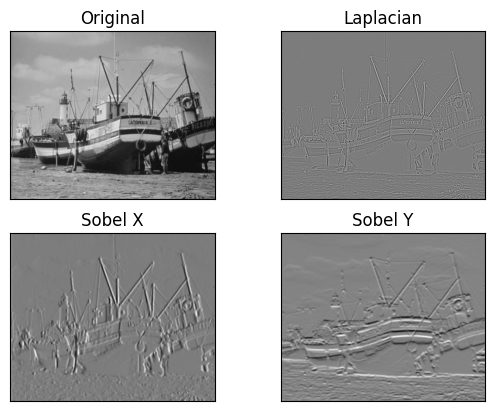

2025-09-28 14:15:42.938 Python[93549:4018395] +[IMKClient subclass]: chose IMKClient_Modern
2025-09-28 14:15:42.938 Python[93549:4018395] +[IMKInputSession subclass]: chose IMKInputSession_Modern


In [1]:
# Image Processing with OpenCV

# Import required libraries
import cv2
import os
import sys
import numpy as np
from matplotlib import pyplot as plt


# Print Python and OpenCV version info
print("Python version")
print (sys.version)
print("Version info.")
print (sys.version_info)
print("OPENCV Version =", cv2.__version__)

# Print current working directory
rep_cour = os.getcwd()
print(rep_cour)

# Load a grayscale image from file
img = cv2.imread('aimagesTPAI2023/data/boats.jpg',0)

# Compute Laplacian (second derivative, edge detection)
laplacian = cv2.Laplacian(img,cv2.CV_64F)

# Compute Sobel gradients (first derivative, edge detection)
sobelx = cv2.Sobel(img,cv2.CV_64F,1,0,ksize=5)
sobely = cv2.Sobel(img,cv2.CV_64F,0,1,ksize=5)

# Display results with Matplotlib (all images in one window)
plt.subplot(2,2,1),plt.imshow(img,cmap = 'gray')
plt.title('Original'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,2),plt.imshow(laplacian,cmap = 'gray')
plt.title('Laplacian'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,3),plt.imshow(sobelx,cmap = 'gray')
plt.title('Sobel X'), plt.xticks([]), plt.yticks([])
plt.subplot(2,2,4),plt.imshow(sobely,cmap = 'gray')
plt.title('Sobel Y'), plt.xticks([]), plt.yticks([])
plt.show()

# Display results with OpenCV (each image in its own window)
cv2.namedWindow("image1", cv2.WINDOW_AUTOSIZE)  
cv2.imshow("image1",img)
cv2.namedWindow("img2", cv2. WINDOW_AUTOSIZE)  
cv2.imshow("image2",laplacian)
cv2.namedWindow("img3", cv2. WINDOW_AUTOSIZE)  
cv2.imshow("img3",sobelx)
cv2.namedWindow("img4", cv2. WINDOW_AUTOSIZE)   
cv2.imshow("img4",sobely)

cv2.waitKey(0) 
cv2.destroyAllWindows()


In [2]:
# Mon script OpenCV : Video_processing

# Import libraries
import numpy as np
import cv2

# Define a function for processing each frame
def frame_processing(imgc):
     return imgc

# Open the video file
cap = cv2.VideoCapture('aimagesTPAI2023/data/jurassicworld.mp4')

# Process the video frames in a loop
while (True):

    # Capture frame-by-frame
    ret, frame = cap.read()

    # If frame is read correctly, process it
    if ret == True:
        # Make a copy of the original frame
        img = frame.copy()
        # Convert frame to grayscale
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Apply custom frame processing (currently just returns the grayscale image)
        gray = frame_processing(gray)

        # Display the original frame
        cv2.imshow('MavideoAvant', frame)
        # Display the processed (grayscale) frame
        cv2.imshow('MavideoApres', gray)

    else:
        print('video ended')
        break

    if cv2.waitKey(1000) & 0xFF == ord('q'):
        break

# When everything done, release the capture
cap.release()
cv2.destroyAllWindows() 

Q2 – Differences between OpenCV and Matplotlib display

With OpenCV each image pops up in its own window. Windows must be managed with extra commands to open and close them.

With Matplotlib, several images and titles can be displayed together in one figure and it works directly in Jupyter notebooks. 

I prefer Matplotlib because it’s easier to compare images side by side.

Partie 1 : Types d’images et statistiques images 

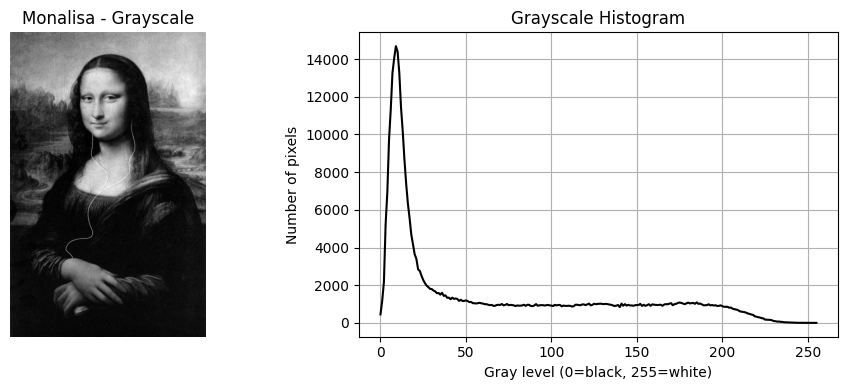

In [6]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread('aimagesTPAI2023/data/monalisa.png', 0)

if img is None:
    print("Error: Image not found!")
else:
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])

    plt.figure(figsize=(10,4))
    
    # Left: grayscale image
    plt.subplot(1,2,1)
    plt.imshow(img, cmap='gray')
    plt.title("Monalisa - Grayscale")
    plt.axis("off")

    # Right: histogram
    plt.subplot(1,2,2)
    plt.plot(hist, color='black')
    plt.title("Grayscale Histogram")
    plt.xlabel("Gray level (0=black, 255=white)")
    plt.ylabel("Number of pixels")
    plt.grid(True)

    plt.tight_layout()
    plt.show()


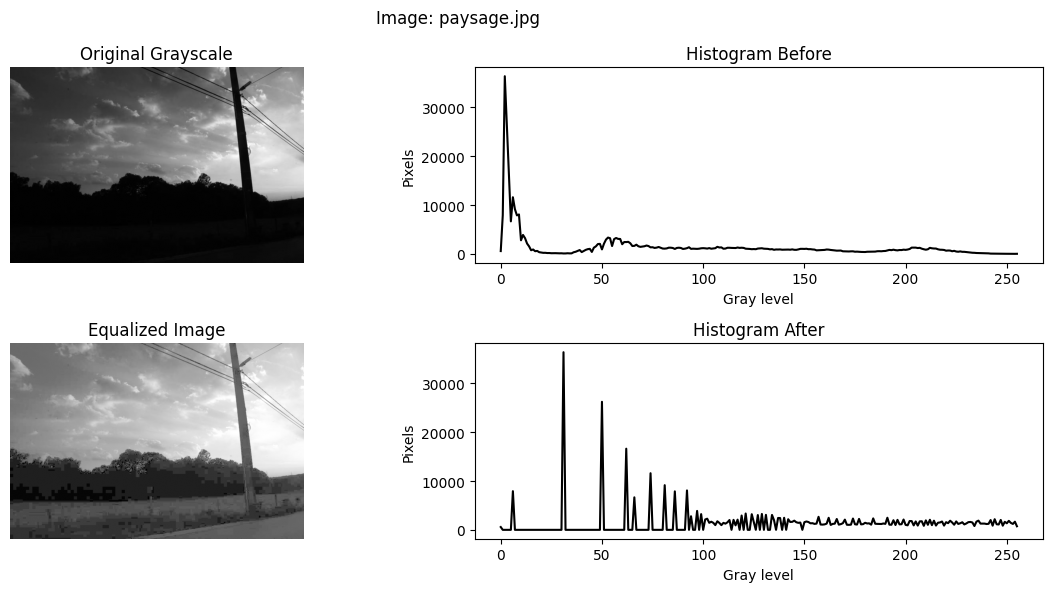

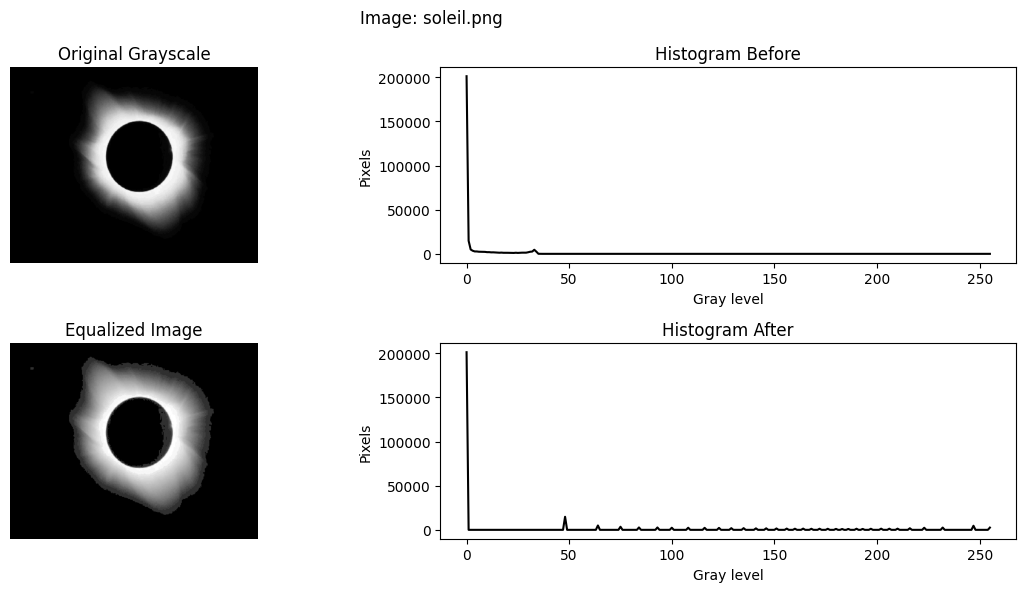

In [8]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# List of images to process
images = ["aimagesTPAI2023/data/paysage.jpg", "aimagesTPAI2023/data/soleil.png"]

for path in images:
    # Load in grayscale
    img = cv2.imread(path, 0)

    if img is None:
        print(f"Error: {path} not found!")
        continue

    # Before equalization
    hist_before = cv2.calcHist([img], [0], None, [256], [0,256])

    # Apply histogram equalization
    img_eq = cv2.equalizeHist(img)

    # After equalization
    hist_after = cv2.calcHist([img_eq], [0], None, [256], [0,256])

    plt.figure(figsize=(12,6))
    plt.suptitle(f"Image: {path.split('/')[-1]}")


    plt.subplot(2,2,1)
    plt.imshow(img, cmap='gray')
    plt.title("Original Grayscale")
    plt.axis("off")

    # Histogram before equalization
    plt.subplot(2,2,2)
    plt.plot(hist_before, color='black')
    plt.title("Histogram Before")
    plt.xlabel("Gray level")
    plt.ylabel("Pixels")

    # Equalized image
    plt.subplot(2,2,3)
    plt.imshow(img_eq, cmap='gray')
    plt.title("Equalized Image")
    plt.axis("off")

    # Histogram after equalization
    plt.subplot(2,2,4)
    plt.plot(hist_after, color='black')
    plt.title("Histogram After")
    plt.xlabel("Gray level")
    plt.ylabel("Pixels")

    plt.tight_layout()
    plt.show()


Partie 2 : Filtrage, convolution, détection de contours 

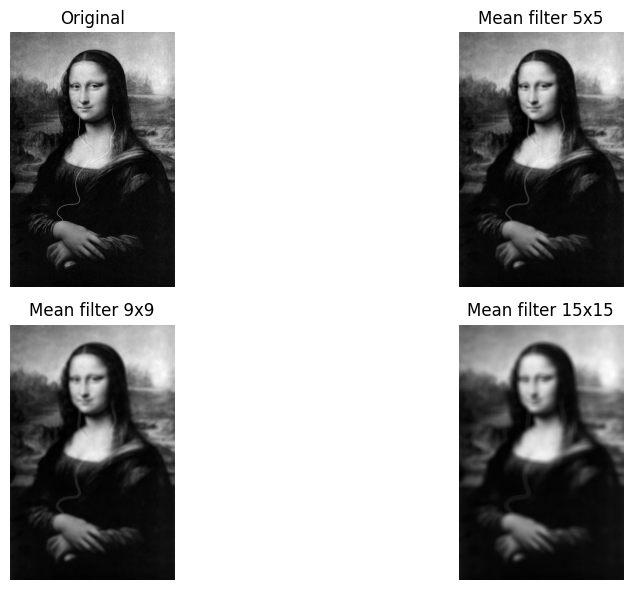

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Load image in grayscale
img = cv2.imread('aimagesTPAI2023/data/monalisa.png', 0)

if img is None:
    print("Error: image not found!")
else:
    # Mean filter with different kernel sizes
    blur_5 = cv2.blur(img, (5,5))
    blur_9 = cv2.blur(img, (9,9))
    blur_15 = cv2.blur(img, (15,15))

    plt.figure(figsize=(12,6))

    plt.subplot(2,2,1)
    plt.imshow(img, cmap='gray')
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2,2,2)
    plt.imshow(blur_5, cmap='gray')
    plt.title("Mean filter 5x5")
    plt.axis("off")

    plt.subplot(2,2,3)
    plt.imshow(blur_9, cmap='gray')
    plt.title("Mean filter 9x9")
    plt.axis("off")

    plt.subplot(2,2,4)
    plt.imshow(blur_15, cmap='gray')
    plt.title("Mean filter 15x15")
    plt.axis("off")

    plt.tight_layout() 
    plt.show()

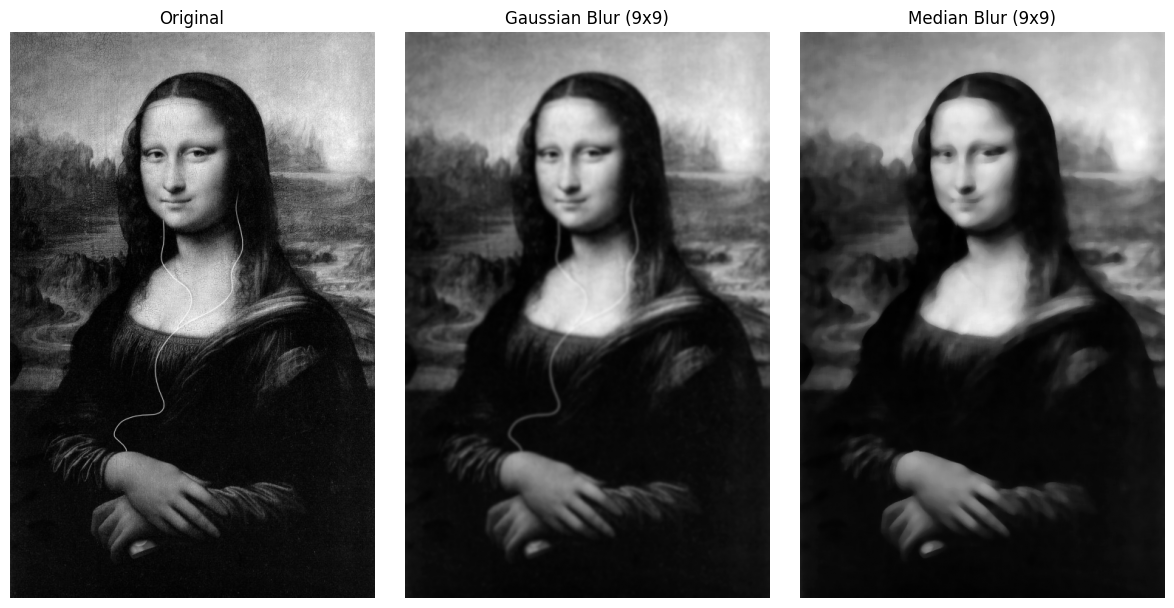

In [27]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread('aimagesTPAI2023/data/monalisa.png', 0)

if img is None:
    print("Error: image not found!")
else:

    gauss = cv2.GaussianBlur(img, (9,9), 0)  
    median = cv2.medianBlur(img, 9)        

  
    plt.figure(figsize=(12,6))

    plt.subplot(1,3,1)
    plt.imshow(img, cmap='gray')
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(gauss, cmap='gray')
    plt.title("Gaussian Blur (9x9)")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(median, cmap='gray')
    plt.title("Median Blur (9x9)")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


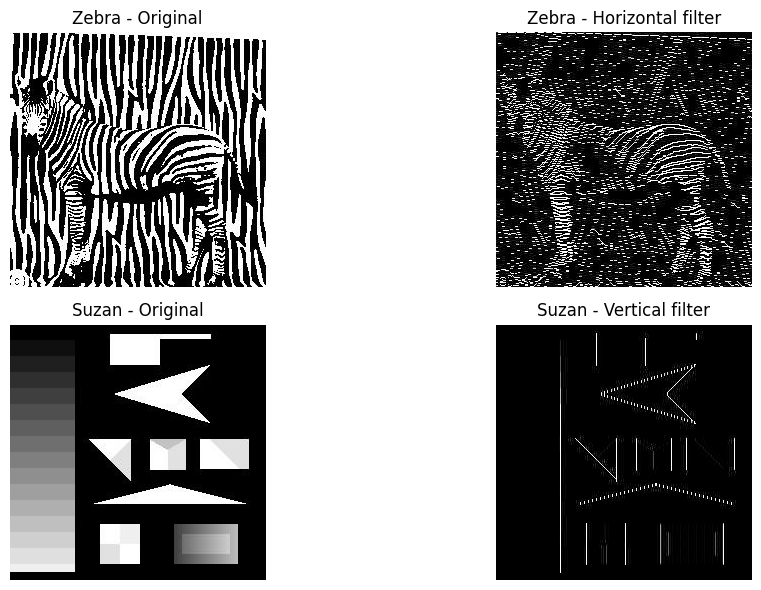

In [28]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Load images in grayscale
zebra = cv2.imread('aimagesTPAI2023/data/zebre.jpg', 0)
suzan = cv2.imread('aimagesTPAI2023/data/suzan.jpg', 0)

if zebra is None or suzan is None:
    print("Error: one of the images not found!")
else:
    # Define convolution kernels (masks)
    kernel_horizontal = np.array([[-1, -1, -1],
                                  [ 2,  2,  2],
                                  [-1, -1, -1]])

    kernel_vertical = np.array([[-1,  2, -1],
                                [-1,  2, -1],
                                [-1,  2, -1]])

    # Apply convolution using filter2D
    zebra_filtered = cv2.filter2D(zebra, -1, kernel_horizontal)
    suzan_filtered = cv2.filter2D(suzan, -1, kernel_vertical)

    # Show results
    plt.figure(figsize=(12,6))

    # Zebre
    plt.subplot(2,2,1)
    plt.imshow(zebra, cmap='gray')
    plt.title("Zebra - Original")
    plt.axis("off")

    plt.subplot(2,2,2)
    plt.imshow(zebra_filtered, cmap='gray')
    plt.title("Zebra - Horizontal filter")
    plt.axis("off")

    # Suzan
    plt.subplot(2,2,3)
    plt.imshow(suzan, cmap='gray')
    plt.title("Suzan - Original")
    plt.axis("off")

    plt.subplot(2,2,4)
    plt.imshow(suzan_filtered, cmap='gray')
    plt.title("Suzan - Vertical filter")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


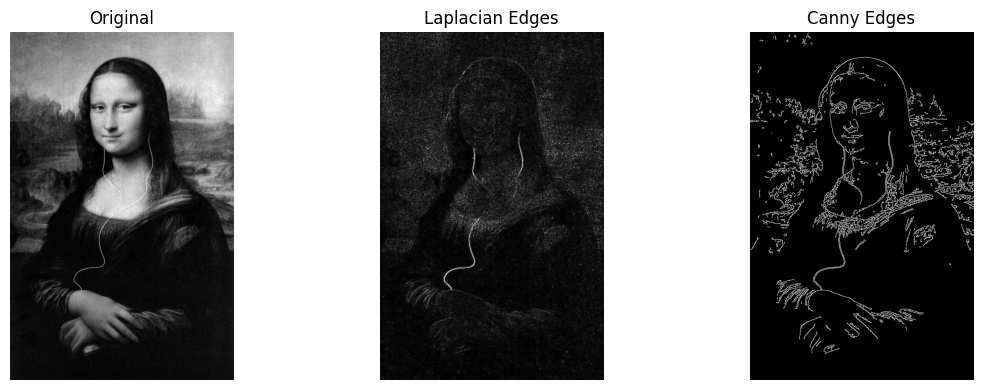

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Load image in grayscale
img = cv2.imread('aimagesTPAI2023/data/monalisa.png', 0)

if img is None:
    print("Error: image not found!")
else:
    # Laplacian edge detection (second derivative)
    laplacian = cv2.Laplacian(img, cv2.CV_64F)
    laplacian = cv2.convertScaleAbs(laplacian)  # convert to 8-bit

    # Canny edge detection
    canny = cv2.Canny(img, 100, 200) 

    # Show results
    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.imshow(img, cmap='gray')
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(laplacian, cmap='gray')
    plt.title("Laplacian Edges")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(canny, cmap='gray')
    plt.title("Canny Edges")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


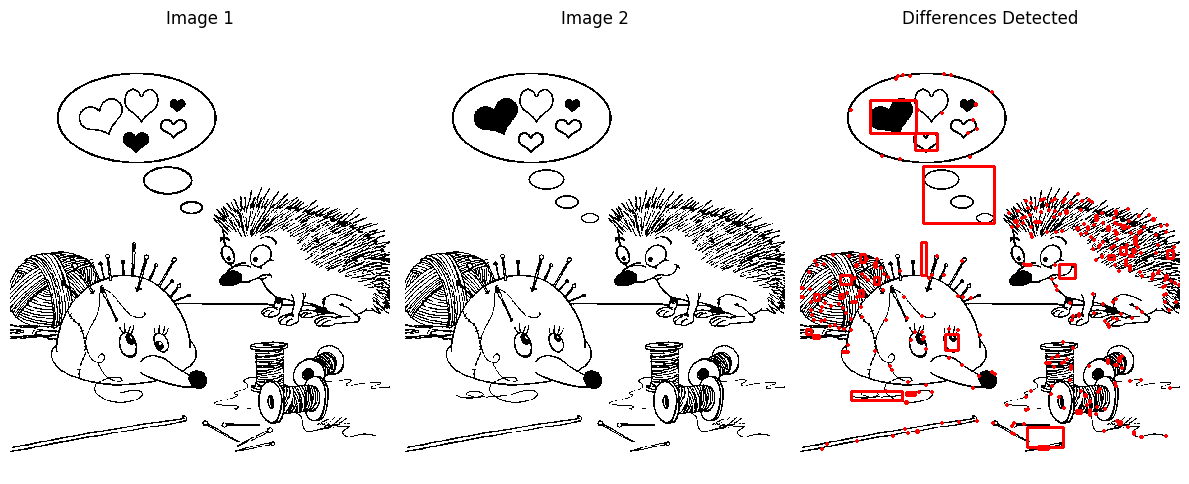

Number of differences found: 328


In [31]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Load images (color)
img1 = cv2.imread("aimagesTPAI2023/data/jeu1.jpg")
img2 = cv2.imread("aimagesTPAI2023/data/jeu2.jpg")

if img1 is None or img2 is None:
    print("Error: one of the images not found!")
else:
    # Convert to grayscale for comparison
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    # Absolute difference
    diff = cv2.absdiff(gray1, gray2)

    # Threshold the difference
    _, diff_bin = cv2.threshold(diff, 50, 255, cv2.THRESH_BINARY)

    # Morphological operations to clean noise
    kernel = np.ones((5,5), np.uint8)
    diff_bin = cv2.morphologyEx(diff_bin, cv2.MORPH_CLOSE, kernel)

    # Find contours of the differences
    contours, _ = cv2.findContours(diff_bin, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Draw bounding boxes around differences on a copy of original
    result = img2.copy()
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        cv2.rectangle(result, (x, y), (x+w, y+h), (0,0,255), 2)  # red boxes

    # Show results
    plt.figure(figsize=(12,6))

    plt.subplot(1,3,1)
    plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB))
    plt.title("Image 1")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    plt.title("Image 2")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title("Differences Detected")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print(f"Number of differences found: {len(contours)}")


Detected cells: 328


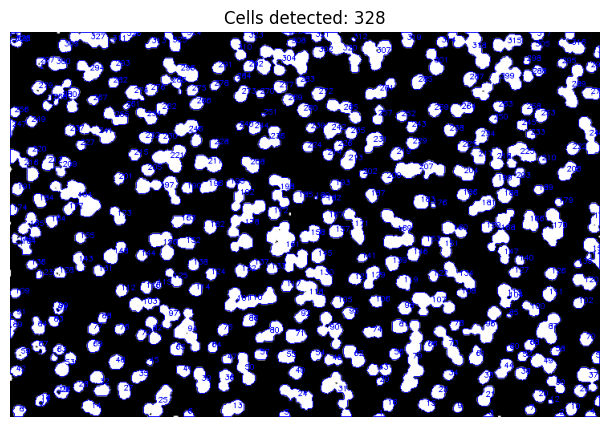

In [122]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread("aimagesTPAI2023/data/cellules.png", 0)

# Step 1: Threshold (Otsu, NOT inverted)
_, thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Step 2: Find all contours (not just external)
contours, _ = cv2.findContours(thresh, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)

# Step 3: Filter contours by area (include smaller cells)
min_area = 8.5 
filtered_contours = [c for c in contours if cv2.contourArea(c) > min_area]

cell_count = len(filtered_contours)
print("Detected cells:", cell_count)

# Draw contours and cell numbers
img_contour = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
for i, c in enumerate(filtered_contours):
    cv2.drawContours(img_contour, [c], -1, (0,0,255), 1)
    M = cv2.moments(c)
    if M["m00"] != 0:
        cx = int(M["m10"]/M["m00"])
        cy = int(M["m01"]/M["m00"])
        cv2.putText(img_contour, str(i+1), (cx, cy), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (0,0,255), 1)

plt.figure(figsize=(10,5))
plt.imshow(img_contour)
plt.title(f"Cells detected: {cell_count}")
plt.axis("off")
plt.show()

Detected cells: 373


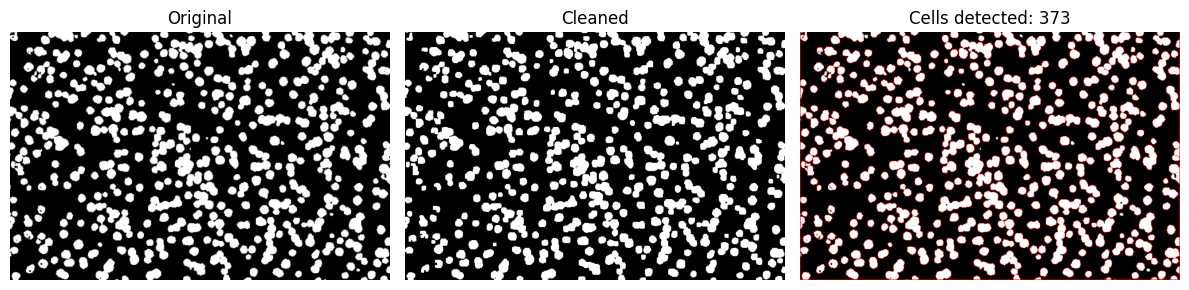

In [9]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread("aimagesTPAI2023/data/cellules.png", 0)

# Threshold (Otsu, NOT inverted)
_, thresh = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Remove small black spots (opening)
kernel = np.ones((3,3), np.uint8)
cleaned = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# Separate stuck cells (distance transform + watershed)
dist_transform = cv2.distanceTransform(cleaned, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.3 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)
sure_bg = cv2.dilate(cleaned, kernel, iterations=3)
unknown = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
cv2.watershed(img_color, markers)
img_color[markers == -1] = [255,0,0]

# Count cells
cell_count = len(np.unique(markers)) - 2
print("Detected cells:", cell_count)

plt.figure(figsize=(12,6))
plt.subplot(1,3,1)
plt.imshow(img, cmap='gray')
plt.title("Original")
plt.axis("off")
plt.subplot(1,3,2)
plt.imshow(cleaned, cmap='gray')
plt.title("Cleaned")
plt.axis("off")
plt.subplot(1,3,3)
plt.imshow(img_color)
plt.title(f"Cells detected: {cell_count}")
plt.axis("off")
plt.tight_layout()
plt.show()


Object 1 SIFT matching results:


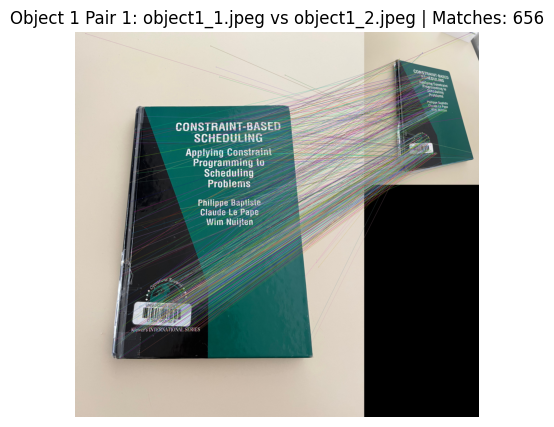

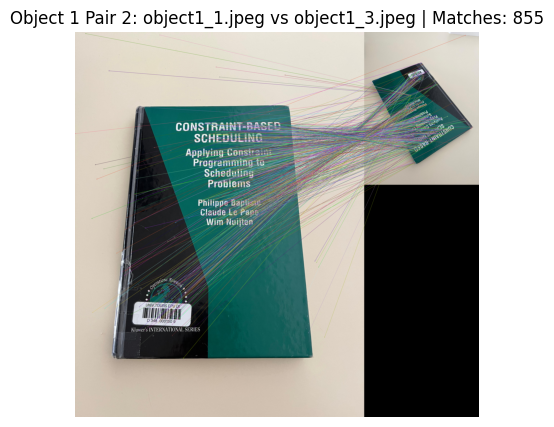

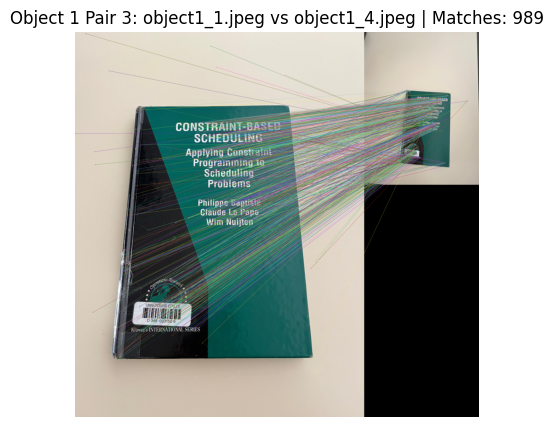

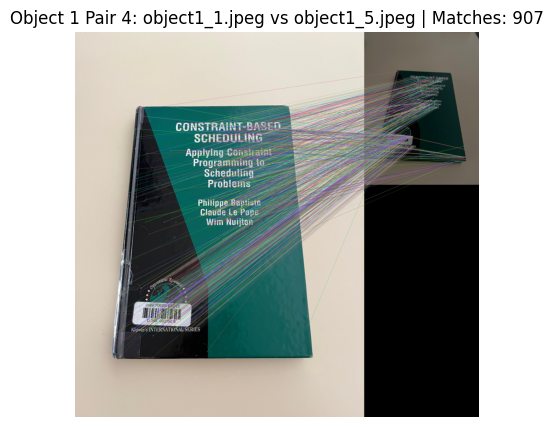

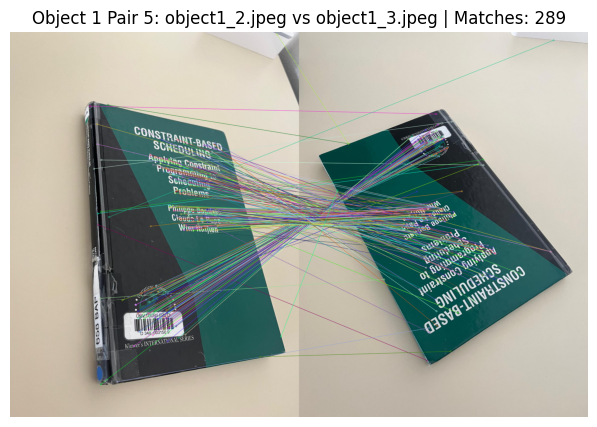

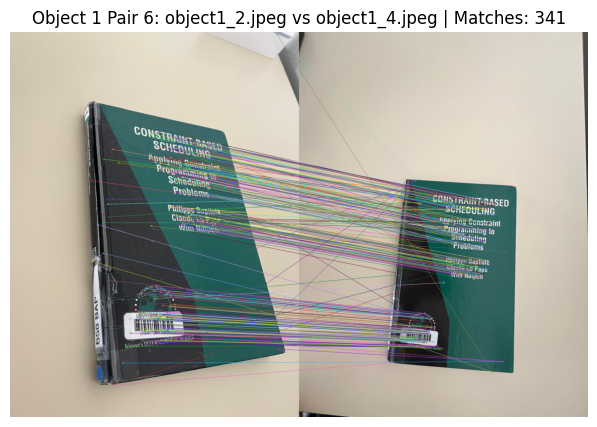

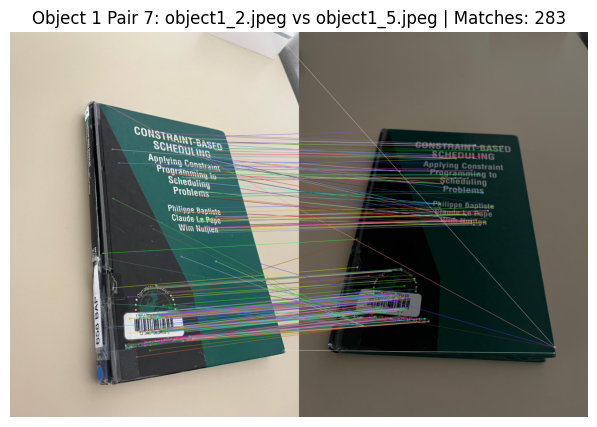

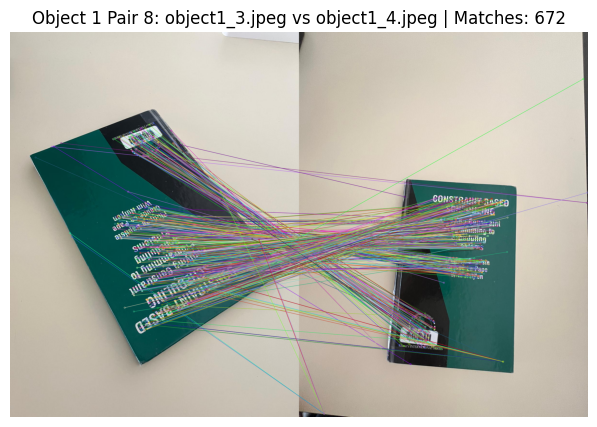

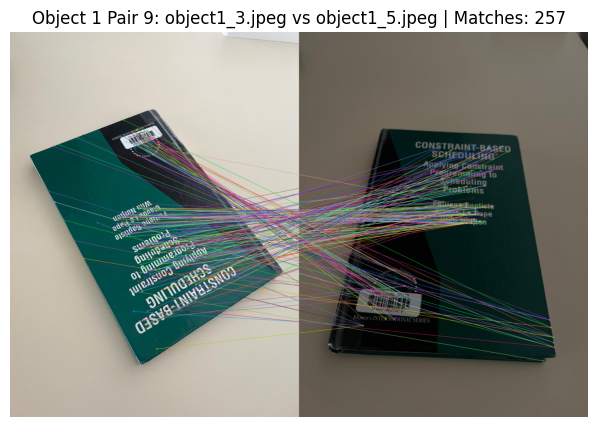

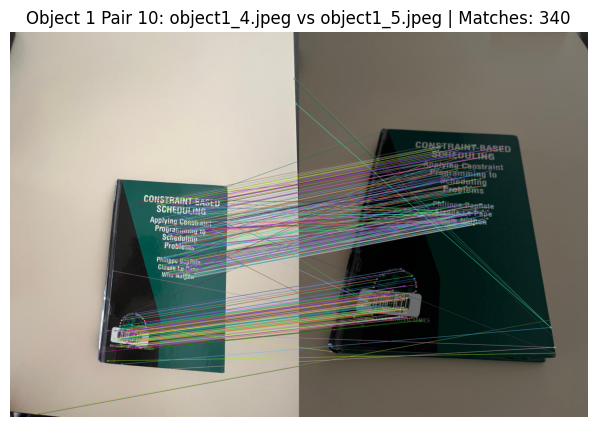


Object 2 SIFT matching results:


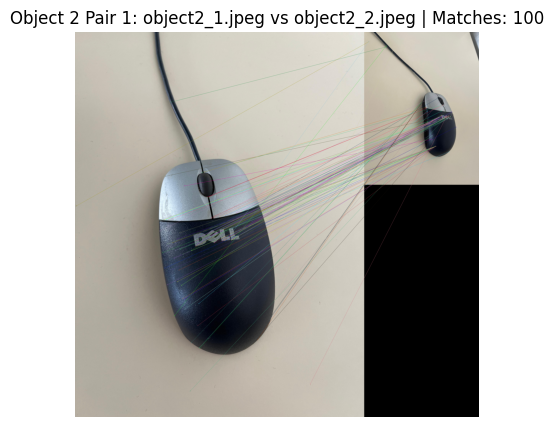

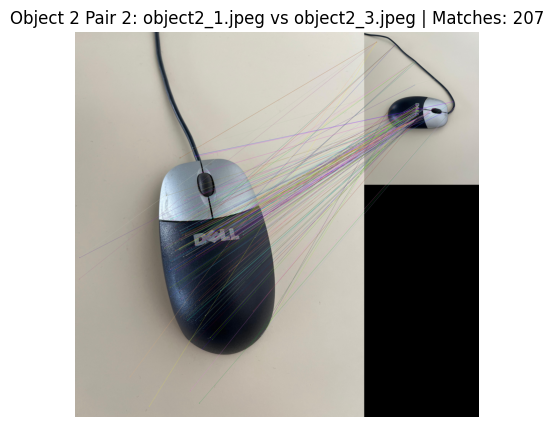

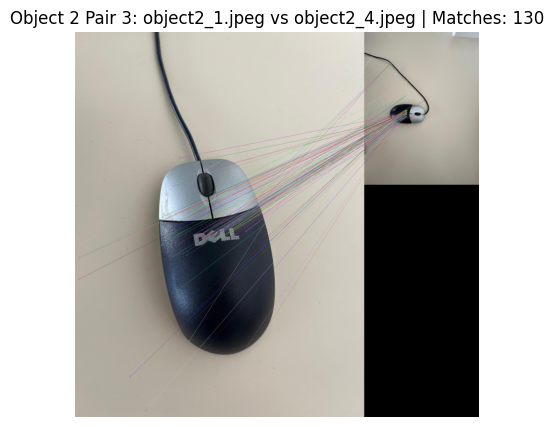

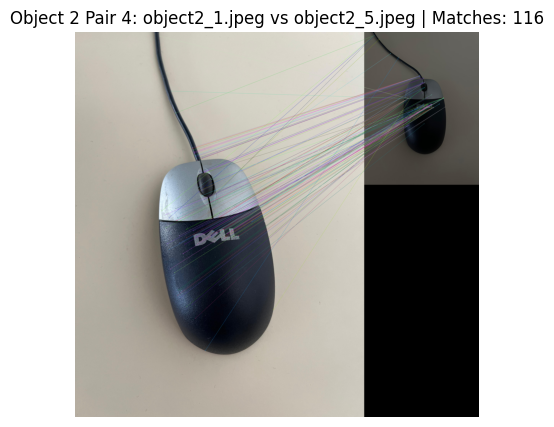

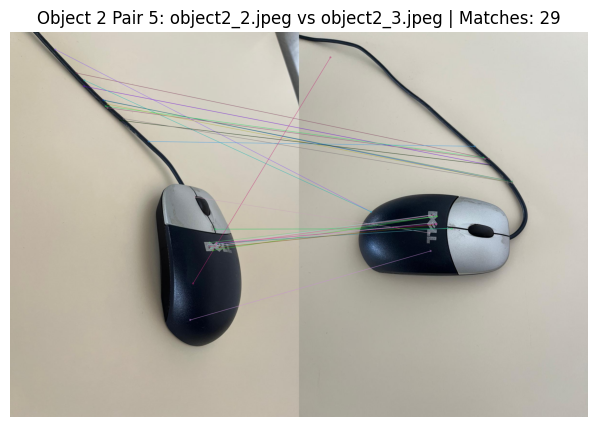

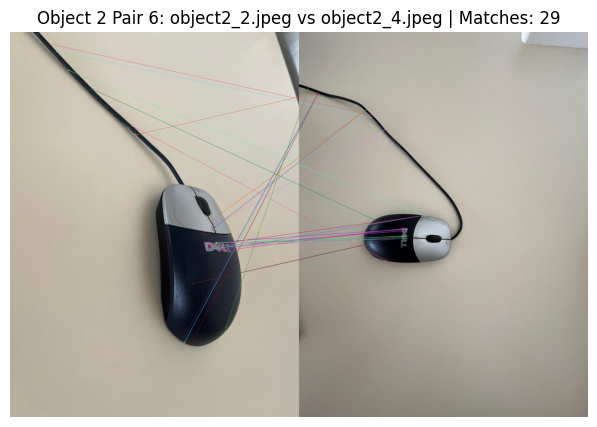

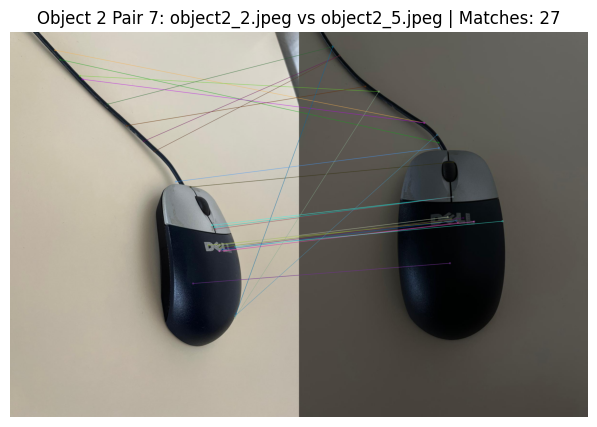

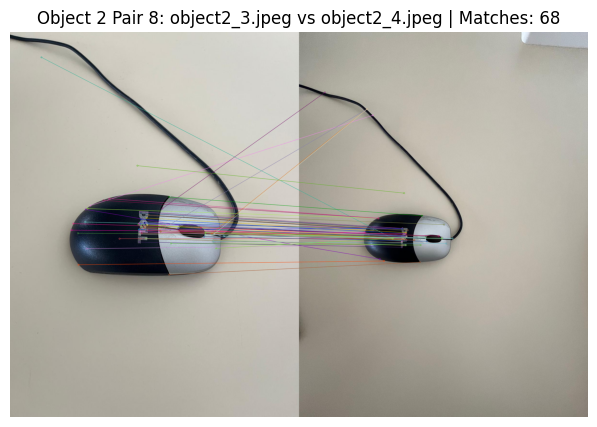

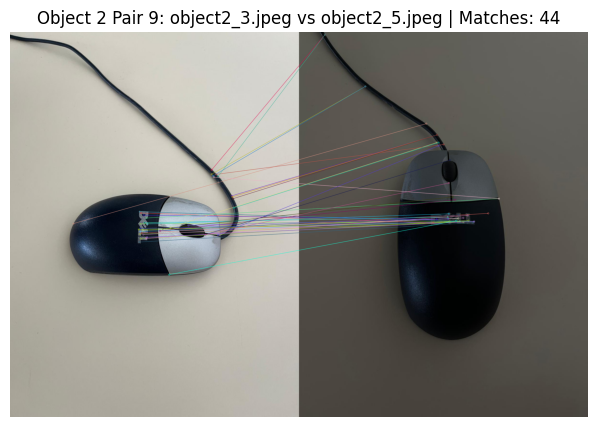

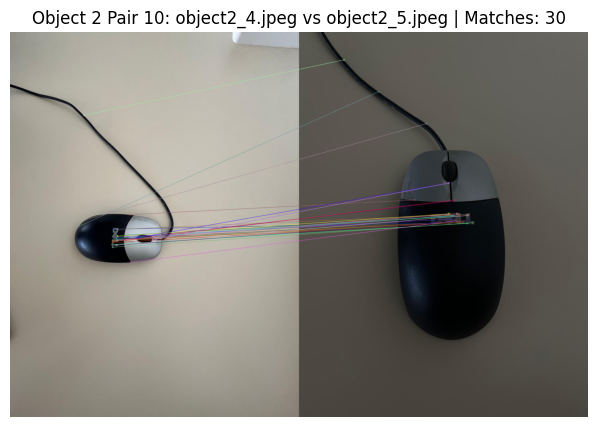


Comments:
- SIFT keypoints are robust to changes in angle, rotation, scale, and lighting.
- More matches between two images means they are more similar.
- Fewer matches means more challenging conditions (e.g., large rotation, scale, or lighting change).
- You should see that images of the same object have many good matches, even with changes.



In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import itertools

def sift_match(img1_path, img2_path):
    # Read images
    img1 = cv2.imread(img1_path)
    img2 = cv2.imread(img2_path)
    gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

    # SIFT detector
    sift = cv2.SIFT_create()
    kp1, des1 = sift.detectAndCompute(gray1, None)
    kp2, des2 = sift.detectAndCompute(gray2, None)

    # Brute-Force matcher with default params
    bf = cv2.BFMatcher()
    matches = bf.knnMatch(des1, des2, k=2)

    # Apply ratio test as per Lowe's paper
    good = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good.append(m)

    # Draw matches
    img_matches = cv2.drawMatches(img1, kp1, img2, kp2, good, None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    return img_matches, len(good)

# List of image paths for each object
object1_imgs = [f'task4/object1_{i}.jpeg' for i in range(1, 6)]
object2_imgs = [f'task4/object2_{i}.jpeg' for i in range(1, 6)]

# For each object, match all unique pairs and display results
for obj_name, img_list in zip(['Object 1', 'Object 2'], [object1_imgs, object2_imgs]):
    pairs = list(itertools.combinations(img_list, 2))
    print(f"\n{obj_name} SIFT matching results:")
    for idx, (imgA, imgB) in enumerate(pairs, 1):
        matched_img, num_matches = sift_match(imgA, imgB)
        plt.figure(figsize=(10, 5))
        plt.imshow(cv2.cvtColor(matched_img, cv2.COLOR_BGR2RGB))
        plt.title(f'{obj_name} Pair {idx}: {imgA.split("/")[-1]} vs {imgB.split("/")[-1]} | Matches: {num_matches}')
        plt.axis('off')
        plt.show()

# Comments:
print("""
Comments:
- SIFT keypoints are robust to changes in angle, rotation, scale, and lighting.
- More matches between two images means they are more similar.
- Fewer matches means more challenging conditions (e.g., large rotation, scale, or lighting change).
- You should see that images of the same object have many good matches, even with changes.
""")


Testing challenges/challenge_0.png


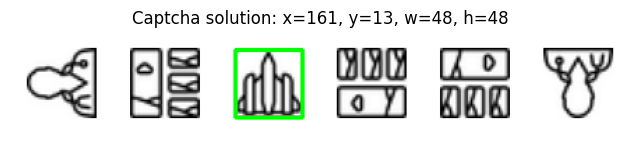

Groups: [3, 3, 1, 2]
Bounding box: (161, 13, 48, 48)

Testing challenges/challenge_1.png


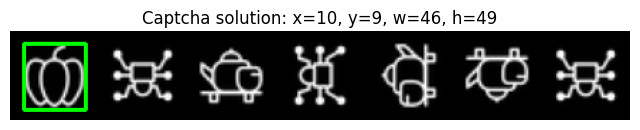

Groups: [3, 3, 1]
Bounding box: (10, 9, 46, 49)

Testing challenges/challenge_2.png


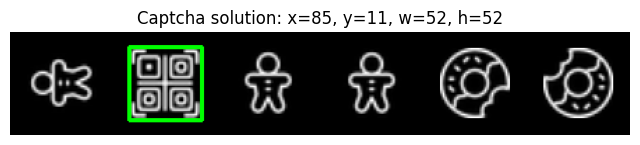

Groups: [3, 2, 1]
Bounding box: (85, 11, 52, 52)

Testing challenges/challenge_3.png


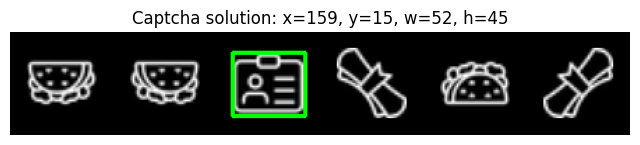

Groups: [3, 1, 2]
Bounding box: (159, 15, 52, 45)

Testing challenges/challenge_4.png


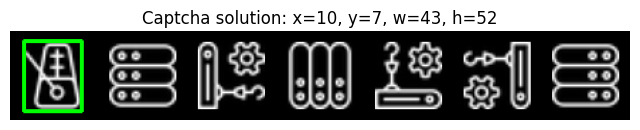

Groups: [6, 3, 1]
Bounding box: (10, 7, 43, 52)

Testing challenges/challenge_5.png


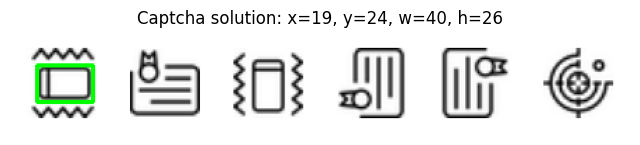

Groups: [1, 3, 1, 1]
Bounding box: (19, 24, 40, 26)

Testing challenges/challenge_6.png


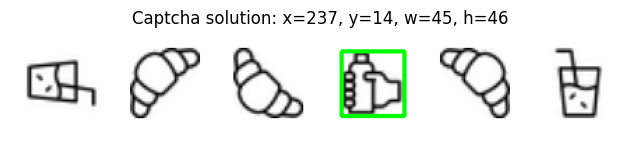

Groups: [2, 1, 3]
Bounding box: (237, 14, 45, 46)

Testing challenges/challenge_7.png


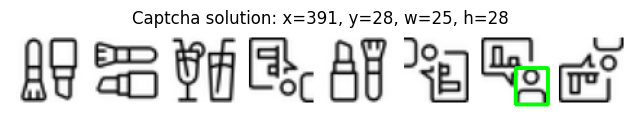

Groups: [3, 3, 1, 3, 1, 3, 1]
Bounding box: (391, 28, 25, 28)

Testing challenges/challenge_8.png


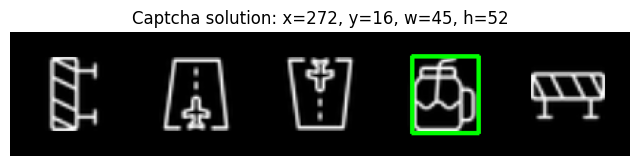

Groups: [4, 2, 1]
Bounding box: (272, 16, 45, 52)

Testing challenges/challenge_9.png


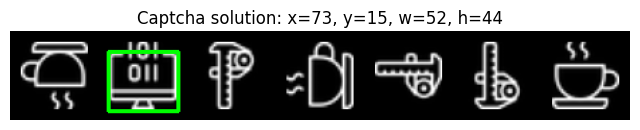

Groups: [3, 3, 1]
Bounding box: (73, 15, 52, 44)


In [27]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def solve_captcha(image_path):
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # Threshold
    if np.mean(gray) > 127:
        _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:
        _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Dilate slightly to connect broken parts
    kernel = np.ones((3,3), np.uint8)
    thresh = cv2.dilate(thresh, kernel, iterations=1)
    
    # Find contours and merge close ones
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    min_dist = 10  # Distance threshold for merging
    merged_contours = []
    used = set()
    
    for i, c1 in enumerate(contours):
        if i in used:
            continue
        current = c1
        x1, y1, w1, h1 = cv2.boundingRect(c1)
        for j, c2 in enumerate(contours[i+1:], i+1):
            if j in used:
                continue
            x2, y2, w2, h2 = cv2.boundingRect(c2)
            # Check if contours are close
            if abs(x1-x2) < min_dist and abs(y1-y2) < min_dist:
                current = np.concatenate([current, c2])
                used.add(j)
        merged_contours.append(current)

    # Process each merged contour
    crops = []
    bboxes = []
    for c in merged_contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > 20 and h > 20 and w*h < gray.shape[0]*gray.shape[1]*0.5:
            # Add padding around crop for better feature detection
            pad = 2
            x1, y1 = max(0, x-pad), max(0, y-pad)
            x2, y2 = min(gray.shape[1], x+w+pad), min(gray.shape[0], y+h+pad)
            crop = gray[y1:y2, x1:x2]
            crops.append(crop)
            bboxes.append((x, y, w, h))

    # SIFT feature extraction (more robust than ORB for rotation)
    sift = cv2.SIFT_create()
    keypoints = []
    descriptors = []
    for crop in crops:
        kp, des = sift.detectAndCompute(crop, None)
        if des is not None:
            keypoints.append(kp)
            descriptors.append(des)
        else:
            keypoints.append([])
            descriptors.append(np.array([]))

    # Group similar icons
    groups = []
    bf = cv2.BFMatcher()
    for i in range(len(descriptors)):
        found = False
        for group in groups:
            matches = bf.knnMatch(descriptors[i], descriptors[group[0]], k=2) if len(descriptors[i]) > 0 and len(descriptors[group[0]]) > 0 else []
            good_matches = []
            for m, n in matches:
                # Make ratio test more strict (0.6 instead of 0.7)
                if m.distance < 0.6 * n.distance:
                    good_matches.append(m)
            # Require more good matches (8 instead of 4)
            if len(good_matches) >= 8:
                # Additional check: verify matches are distributed
                src_pts = np.float32([keypoints[i][m.queryIdx].pt for m in good_matches])
                dst_pts = np.float32([keypoints[group[0]][m.trainIdx].pt for m in good_matches])
                if len(set([tuple(p) for p in src_pts])) >= 4:  # At least 4 unique points
                    group.append(i)
                    found = True
                    break
        if not found:
            groups.append([i])

    # Find the group with minimum count
    # Find group with least members but valid size
    valid_groups = [g for g in groups if len(g) <= 3]  # Most icons appear 3+ times
    if valid_groups:
        min_group = min(valid_groups, key=len)
    else:
        min_group = min(groups, key=len)
    idx = min_group[0]
    x, y, w, h = bboxes[idx]
    
    # Visualize result
    img_box = img.copy()
    cv2.rectangle(img_box, (x, y), (x+w, y+h), (0,255,0), 2)
    plt.figure(figsize=(8,4))
    plt.imshow(cv2.cvtColor(img_box, cv2.COLOR_BGR2RGB))
    plt.title(f'Captcha solution: x={x}, y={y}, w={w}, h={h}')
    plt.axis('off')
    plt.show()
    
    # Print group sizes for debugging
    print("Groups:", [len(g) for g in groups])
    
    return (x, y, w, h)

# Test images
test_images = [f'challenges/challenge_{i}.png' for i in range(10)]
for img_path in test_images:
    print(f"\nTesting {img_path}")
    bbox = solve_captcha(img_path)
    print("Bounding box:", bbox)


Testing challenges/challenge_0.png


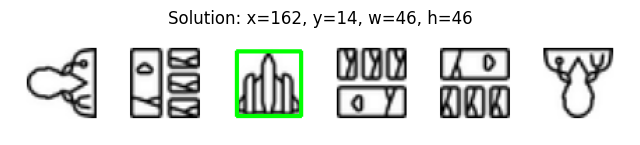

Bounding box: (162, 14, 46, 46)

Testing challenges/challenge_1.png


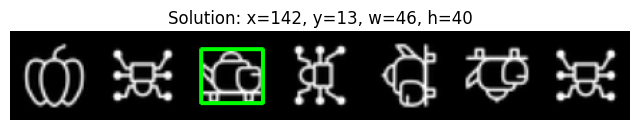

Bounding box: (142, 13, 46, 40)

Testing challenges/challenge_2.png


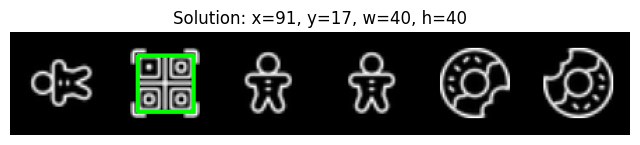

Bounding box: (91, 17, 40, 40)

Testing challenges/challenge_3.png


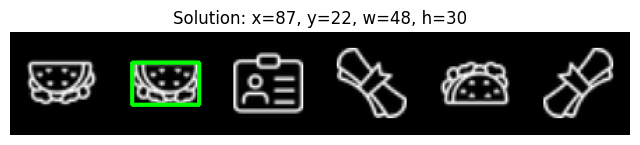

Bounding box: (87, 22, 48, 30)

Testing challenges/challenge_4.png


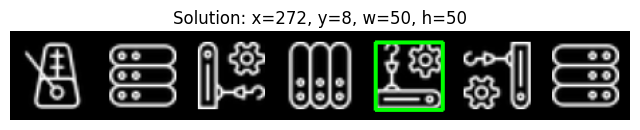

Bounding box: (272, 8, 50, 50)

Testing challenges/challenge_5.png


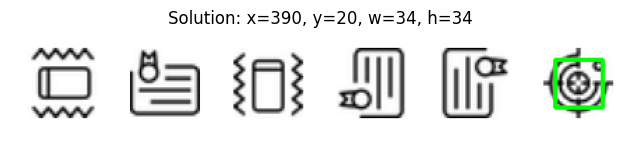

Bounding box: (390, 20, 34, 34)

Testing challenges/challenge_6.png


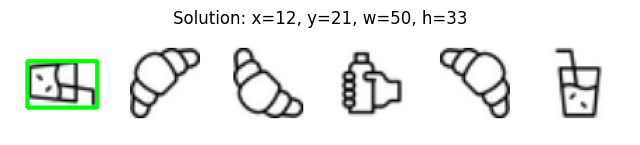

Bounding box: (12, 21, 50, 33)

Testing challenges/challenge_7.png


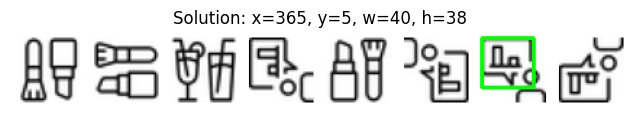

Bounding box: (365, 5, 40, 38)

Testing challenges/challenge_8.png


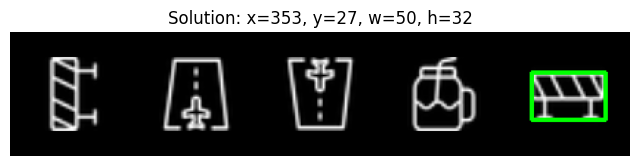

Bounding box: (353, 27, 50, 32)

Testing challenges/challenge_9.png


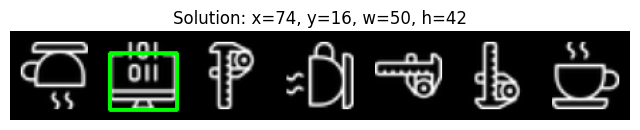

Bounding box: (74, 16, 50, 42)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

def icon_similar(icon1, icon2, threshold=0.7):
    """Return True if two icons are similar under any rotation."""
    for k in range(4):  # 0, 90, 180, 270
        rotated = np.rot90(icon2, k)
        score = ssim(icon1, rotated)
        if score > threshold:
            return True
å    return False

def solve_captcha(image_path):
    # 1. Load & grayscale
    img = cv2.imread(image_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 2. Threshold (svijetla/tamna pozadina)
    if np.mean(gray) > 127:
        _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    else:
        _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 3. Find contours
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    icons, positions = [], []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > 20 and h > 20:
            icon = gray[y:y+h, x:x+w]
            icon = cv2.resize(icon, (64, 64))
            icons.append(icon)
            positions.append((x, y, w, h))

    # 4. Group icons by rotation-invariant similarity
    groups = []
    used = set()
    for i in range(len(icons)):
        if i in used:
            continue
        group = [i]
        used.add(i)
        for j in range(i+1, len(icons)):
            if j in used:
                continue
            if icon_similar(icons[i], icons[j]):
                group.append(j)
                used.add(j)
        groups.append(group)

    # 5. Find the smallest group (unique icon)
    min_group = min(groups, key=len)
    idx = min_group[0]
    x, y, w, h = positions[idx]

    # 6. Draw result
    img_box = img.copy()
    cv2.rectangle(img_box, (x, y), (x+w, y+h), (0,255,0), 2)
    plt.figure(figsize=(8,4))
    plt.imshow(cv2.cvtColor(img_box, cv2.COLOR_BGR2RGB))
    plt.title(f'Solution: x={x}, y={y}, w={w}, h={h}')
    plt.axis('off')
    plt.show()

    return (x, y, w, h)

# Primjer:
test_images = [f'challenges/challenge_{i}.png' for i in range(10)]
for img_path in test_images:
    print(f"\nTesting {img_path}")
    bbox = solve_captcha(img_path)
    print("Bounding box:", bbox)
